In [170]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/zomato-dataset/zomato.csv


In [171]:
import numpy as np
import pandas as pd
df = pd.read_csv('/kaggle/input/zomato-dataset/zomato.csv')
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


### Data Cleaning

In [172]:
df.shape

(51717, 17)

In [173]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='object')

In [174]:
df.size

879189

### Explore the dataset info, describe and find columns with categories, and numeric columns as well.

In [175]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   url                          51717 non-null  object
 1   address                      51717 non-null  object
 2   name                         51717 non-null  object
 3   online_order                 51717 non-null  object
 4   book_table                   51717 non-null  object
 5   rate                         43942 non-null  object
 6   votes                        51717 non-null  int64 
 7   phone                        50509 non-null  object
 8   location                     51696 non-null  object
 9   rest_type                    51490 non-null  object
 10  dish_liked                   23639 non-null  object
 11  cuisines                     51672 non-null  object
 12  approx_cost(for two people)  51371 non-null  object
 13  reviews_list                 51

In [176]:
df.describe().head()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000


In [177]:
df.isna().sum().head()

url             0
address         0
name            0
online_order    0
book_table      0
dtype: int64

In [178]:
df.nunique()

url                            51717
address                        11495
name                            8792
online_order                       2
book_table                         2
rate                              64
votes                           2328
phone                          14926
location                          93
rest_type                         93
dish_liked                      5271
cuisines                        2723
approx_cost(for two people)       70
reviews_list                   22513
menu_item                       9098
listed_in(type)                    7
listed_in(city)                   30
dtype: int64

In [179]:
df.drop(['url', 'address',"phone",'dish_liked','menu_item','reviews_list'],axis = 1, inplace = True)

df.head()

,name,online_order,book_table,rate,votes,location,rest_type,cuisines,approx_cost(for two people),listed_in(type),listed_in(city)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


In [180]:
df.head()

,name,online_order,book_table,rate,votes,location,rest_type,cuisines,approx_cost(for two people),listed_in(type),listed_in(city)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


### Deleting Redudant Columns

In [181]:
df.dropna(how='any', inplace = True)
df.isnull().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
cuisines                       0
approx_cost(for two people)    0
listed_in(type)                0
listed_in(city)                0
dtype: int64

### Renaming the Columns

In [182]:
df.rename(columns = {'url':'URL','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'address':'Address','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'name':'Name','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'online_order':'Online_Orders','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'book_table':'Table_Booking','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'phone':'Phone_no','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'rate':"Rate",'listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'votes':'Votes','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'location':'Location','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'rest_type':'Restaurant','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'dish_liked':'Dishes_liked','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'cuisines':'Cusines','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'approx_cost(for two people)':'Cost','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'reviews_list':'Reviews','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'menu_item':'Menu_item','listed_in(type)':'Type'},inplace=True)
df.rename(columns = {'listed_in(city)':'Listed_in(City)','listed_in(type)':'Type'},inplace=True)
df.head()

,Name,Online_Orders,Table_Booking,Rate,Votes,Location,Restaurant,Cusines,Cost,Type,Listed_in(City)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


### Dropping Duplicates

In [183]:
df.drop_duplicates()
df.head()

,Name,Online_Orders,Table_Booking,Rate,Votes,Location,Restaurant,Cusines,Cost,Type,Listed_in(City)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


In [184]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

0

### Cleaning Individual Columns

In [185]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 43447 entries, 0 to 51716
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Name             43447 non-null  object
 1   Online_Orders    43447 non-null  object
 2   Table_Booking    43447 non-null  object
 3   Rate             43447 non-null  object
 4   Votes            43447 non-null  int64 
 5   Location         43447 non-null  object
 6   Restaurant       43447 non-null  object
 7   Cusines          43447 non-null  object
 8   Cost             43447 non-null  object
 9   Type             43447 non-null  object
 10  Listed_in(City)  43447 non-null  object
dtypes: int64(1), object(10)
memory usage: 4.0+ MB


In [186]:
df.describe()

,Votes
count,43447.000000
mean,333.777430
std,863.748802
min,0.000000
25%,17.000000
50%,64.000000
75%,254.000000
max,16832.000000


### Rename the NaN values from the dataset

In [187]:
df.isnull().sum()
df.dropna(how='any',inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 43447 entries, 0 to 51716
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Name             43447 non-null  object
 1   Online_Orders    43447 non-null  object
 2   Table_Booking    43447 non-null  object
 3   Rate             43447 non-null  object
 4   Votes            43447 non-null  int64 
 5   Location         43447 non-null  object
 6   Restaurant       43447 non-null  object
 7   Cusines          43447 non-null  object
 8   Cost             43447 non-null  object
 9   Type             43447 non-null  object
 10  Listed_in(City)  43447 non-null  object
dtypes: int64(1), object(10)
memory usage: 4.0+ MB


### Check for some Transformations 

In [188]:
df.Votes
df.head()

,Name,Online_Orders,Table_Booking,Rate,Votes,Location,Restaurant,Cusines,Cost,Type,Listed_in(City)
0,Jalsa,Yes,Yes,4.1/5,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1/5,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8/5,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8/5,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


In [189]:
df['Votes'] = df['Votes'].astype(str)
df['Votes'] = df['Votes'].apply(lambda x : x.replace(',',','))
df['Votes'] = df['Votes'].astype(float)
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 43447 entries, 0 to 51716
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             43447 non-null  object 
 1   Online_Orders    43447 non-null  object 
 2   Table_Booking    43447 non-null  object 
 3   Rate             43447 non-null  object 
 4   Votes            43447 non-null  float64
 5   Location         43447 non-null  object 
 6   Restaurant       43447 non-null  object 
 7   Cusines          43447 non-null  object 
 8   Cost             43447 non-null  object 
 9   Type             43447 non-null  object 
 10  Listed_in(City)  43447 non-null  object 
dtypes: float64(1), object(10)
memory usage: 4.0+ MB


### Cleaning Rate

In [190]:
def handle_Rate(value):
    if(value=='NEW' or value=='-'):
        return np.nan
    else:
        value=str(value).split('/')
        value=value[0]
        return float(value)
df['Rate']=df['Rate'].apply(handle_Rate)
df['Rate'].head()

0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: Rate, dtype: float64

In [191]:
df.head()

,Name,Online_Orders,Table_Booking,Rate,Votes,Location,Restaurant,Cusines,Cost,Type,Listed_in(City)
0,Jalsa,Yes,Yes,4.1,775.0,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1,787.0,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8,918.0,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7,88.0,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8,166.0,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


In [192]:
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

In [193]:
df.dtypes

Name                object
Online_Orders       object
Table_Booking       object
Rate               float64
Votes              float64
Location            object
Restaurant          object
Cusines             object
Cost                object
Type                object
Listed_in(City)     object
dtype: object

### Data Visualization:

### 1. Restaurants delivering Online or not

Text(0.5, 1.0, 'Restaurants delivering Online or not')

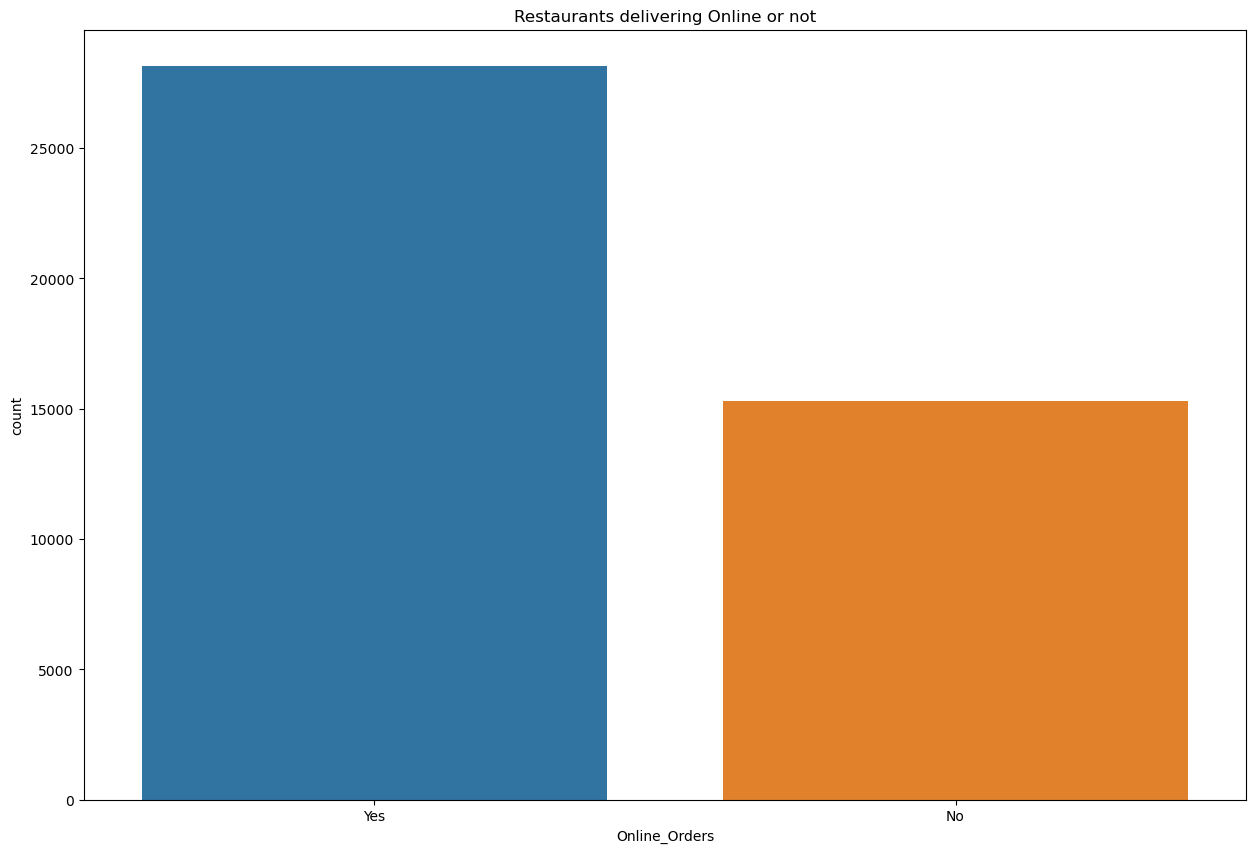

In [194]:
plt.figure(figsize=(15, 10))
sns.countplot(x ='Online_Orders', data = df)
plt.title('Restaurants delivering Online or not')

### 2. Restaurants allowing table booking or not

Text(0.5, 1.0, 'Restaurants allowing table booking or not')

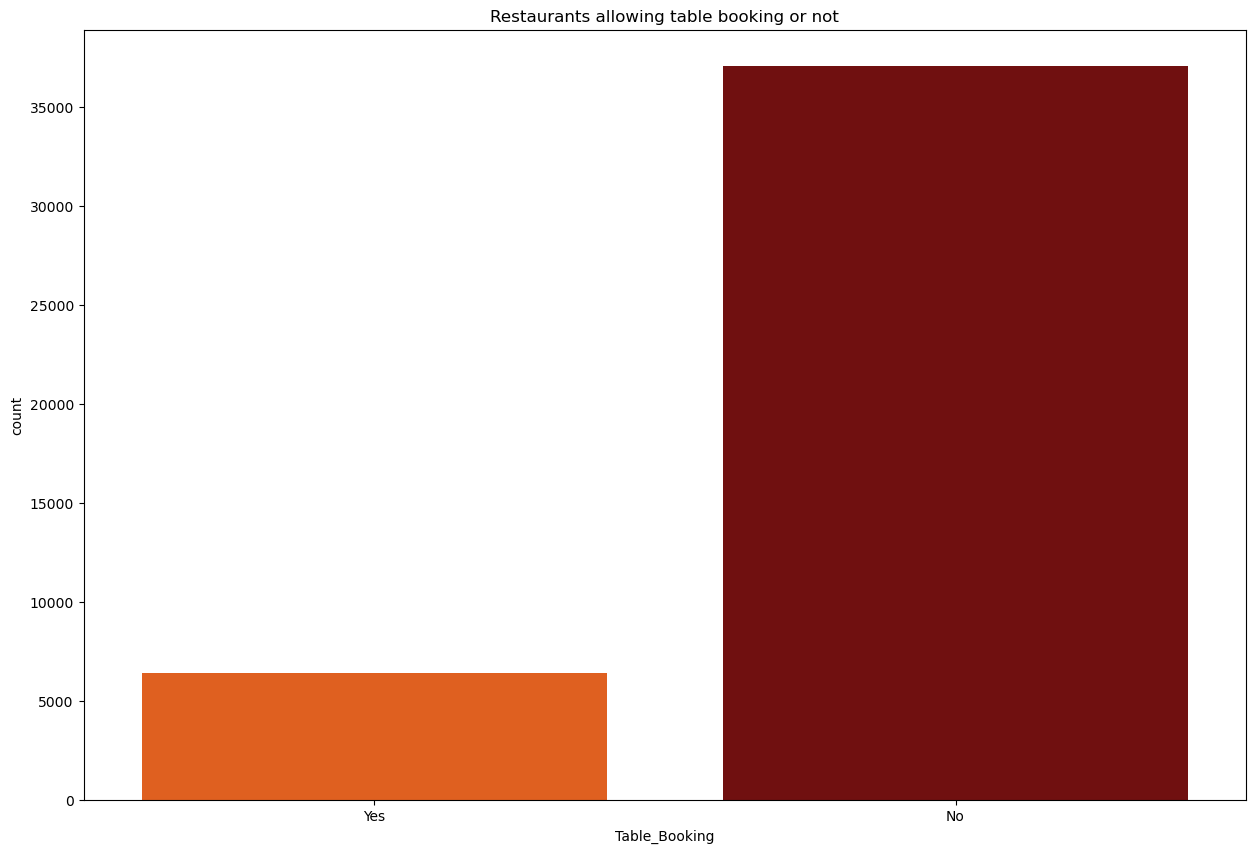

In [195]:
plt.subplots(figsize=(15, 10))
sns.countplot(x ='Table_Booking', data = df, palette='gist_heat_r')
plt.title('Restaurants allowing table booking or not')

### 3. Table booking Rate vs Rate

In [196]:
df.Rate.apply(lambda r: str(r).split('/')[0]).head()

0    4.1
1    4.1
2    3.8
3    3.7
4    3.8
Name: Rate, dtype: object

In [197]:
df.head()

,Name,Online_Orders,Table_Booking,Rate,Votes,Location,Restaurant,Cusines,Cost,Type,Listed_in(City)
0,Jalsa,Yes,Yes,4.1,775.0,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1,787.0,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8,918.0,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7,88.0,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8,166.0,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


In [198]:
pd.set_option("display.max.rows", None)
c = df.groupby('Location')['Rate','Cost'].mean()
loc_df = pd.DataFrame(c)
loc_df['Count'] = df['Location'].value_counts()
loc_df.sort_values(by=['Count', 'Rate'],ascending = False).head(10)

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:2: FutureWarning: Indexing with multiple keys (implicitly converted to a tuple of keys) will be deprecated, use a list instead.
  


,Rate,Count
Location,,
BTM,3.571547,4201
Koramangala 5th Block,4.006710,2356
HSR,3.678213,2100
Indiranagar,3.831532,1882
JP Nagar,3.677544,1841
Jayanagar,3.780171,1709
Whitefield,3.624745,1677
Marathahalli,3.545700,1467
Bannerghatta Road,3.509722,1312


### 4. Best Location

<AxesSubplot:ylabel='Name'>

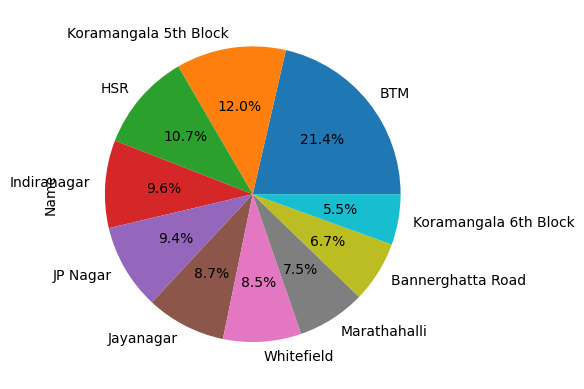

In [199]:
df.groupby('Location')['Name'].count().nlargest(10).plot(kind = 'pie', autopct = '%1.1f%%')

### 5. Relation between Location and Rating

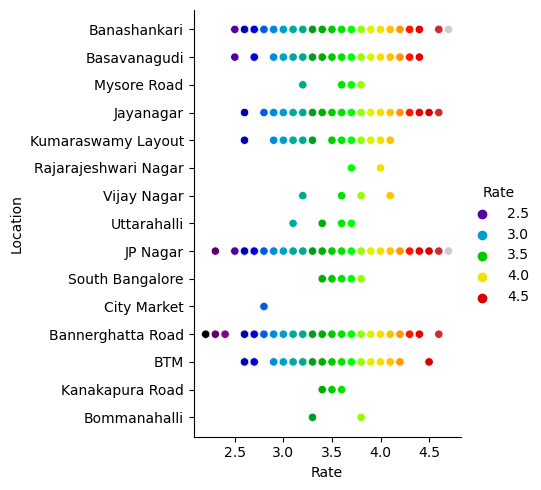

In [200]:
sns.relplot(data = df.head(2000), x='Rate', y='Location', hue='Rate', kind='scatter', palette='nipy_spectral')

### 6. Restaurant Type

<AxesSubplot:ylabel='Restaurant'>

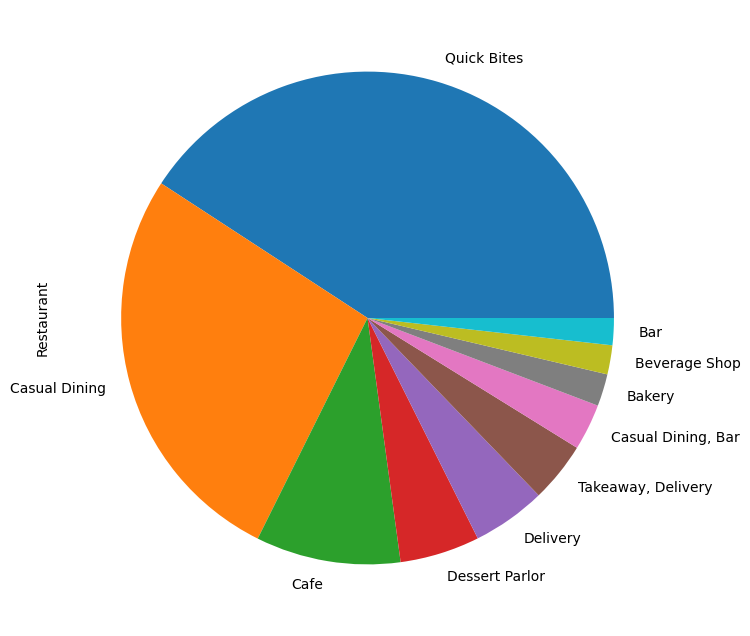

In [201]:
fig = plt.subplots(figsize = (10, 8))
df['Restaurant'].value_counts().head(10).plot(kind = 'pie')

### 7. Gaussian Rest type and Rating

In [202]:
x = df['Restaurant'].unique()
print(x)
y = df['Rate'].min()
print(y)

['Casual Dining' 'Cafe, Casual Dining' 'Quick Bites' 'Casual Dining, Cafe'
 'Cafe' 'Quick Bites, Cafe' 'Cafe, Quick Bites' 'Delivery' 'Mess'
 'Dessert Parlor' 'Bakery, Dessert Parlor' 'Pub' 'Bakery'
 'Takeaway, Delivery' 'Fine Dining' 'Beverage Shop' 'Sweet Shop' 'Bar'
 'Dessert Parlor, Sweet Shop' 'Bakery, Quick Bites'
 'Sweet Shop, Quick Bites' 'Kiosk' 'Food Truck'
 'Quick Bites, Dessert Parlor' 'Beverage Shop, Quick Bites'
 'Beverage Shop, Dessert Parlor' 'Takeaway' 'Pub, Casual Dining'
 'Casual Dining, Bar' 'Dessert Parlor, Beverage Shop'
 'Quick Bites, Bakery' 'Microbrewery, Casual Dining' 'Lounge'
 'Bar, Casual Dining' 'Food Court' 'Cafe, Bakery' 'Dhaba'
 'Quick Bites, Sweet Shop' 'Microbrewery' 'Food Court, Quick Bites'
 'Quick Bites, Beverage Shop' 'Pub, Bar' 'Casual Dining, Pub'
 'Lounge, Bar' 'Dessert Parlor, Quick Bites' 'Food Court, Dessert Parlor'
 'Casual Dining, Sweet Shop' 'Food Court, Casual Dining'
 'Casual Dining, Microbrewery' 'Lounge, Casual Dining' 'Cafe, Food Cou

In [203]:
df.dtypes

Name                object
Online_Orders       object
Table_Booking       object
Rate               float64
Votes              float64
Location            object
Restaurant          object
Cusines             object
Cost                object
Type                object
Listed_in(City)     object
dtype: object

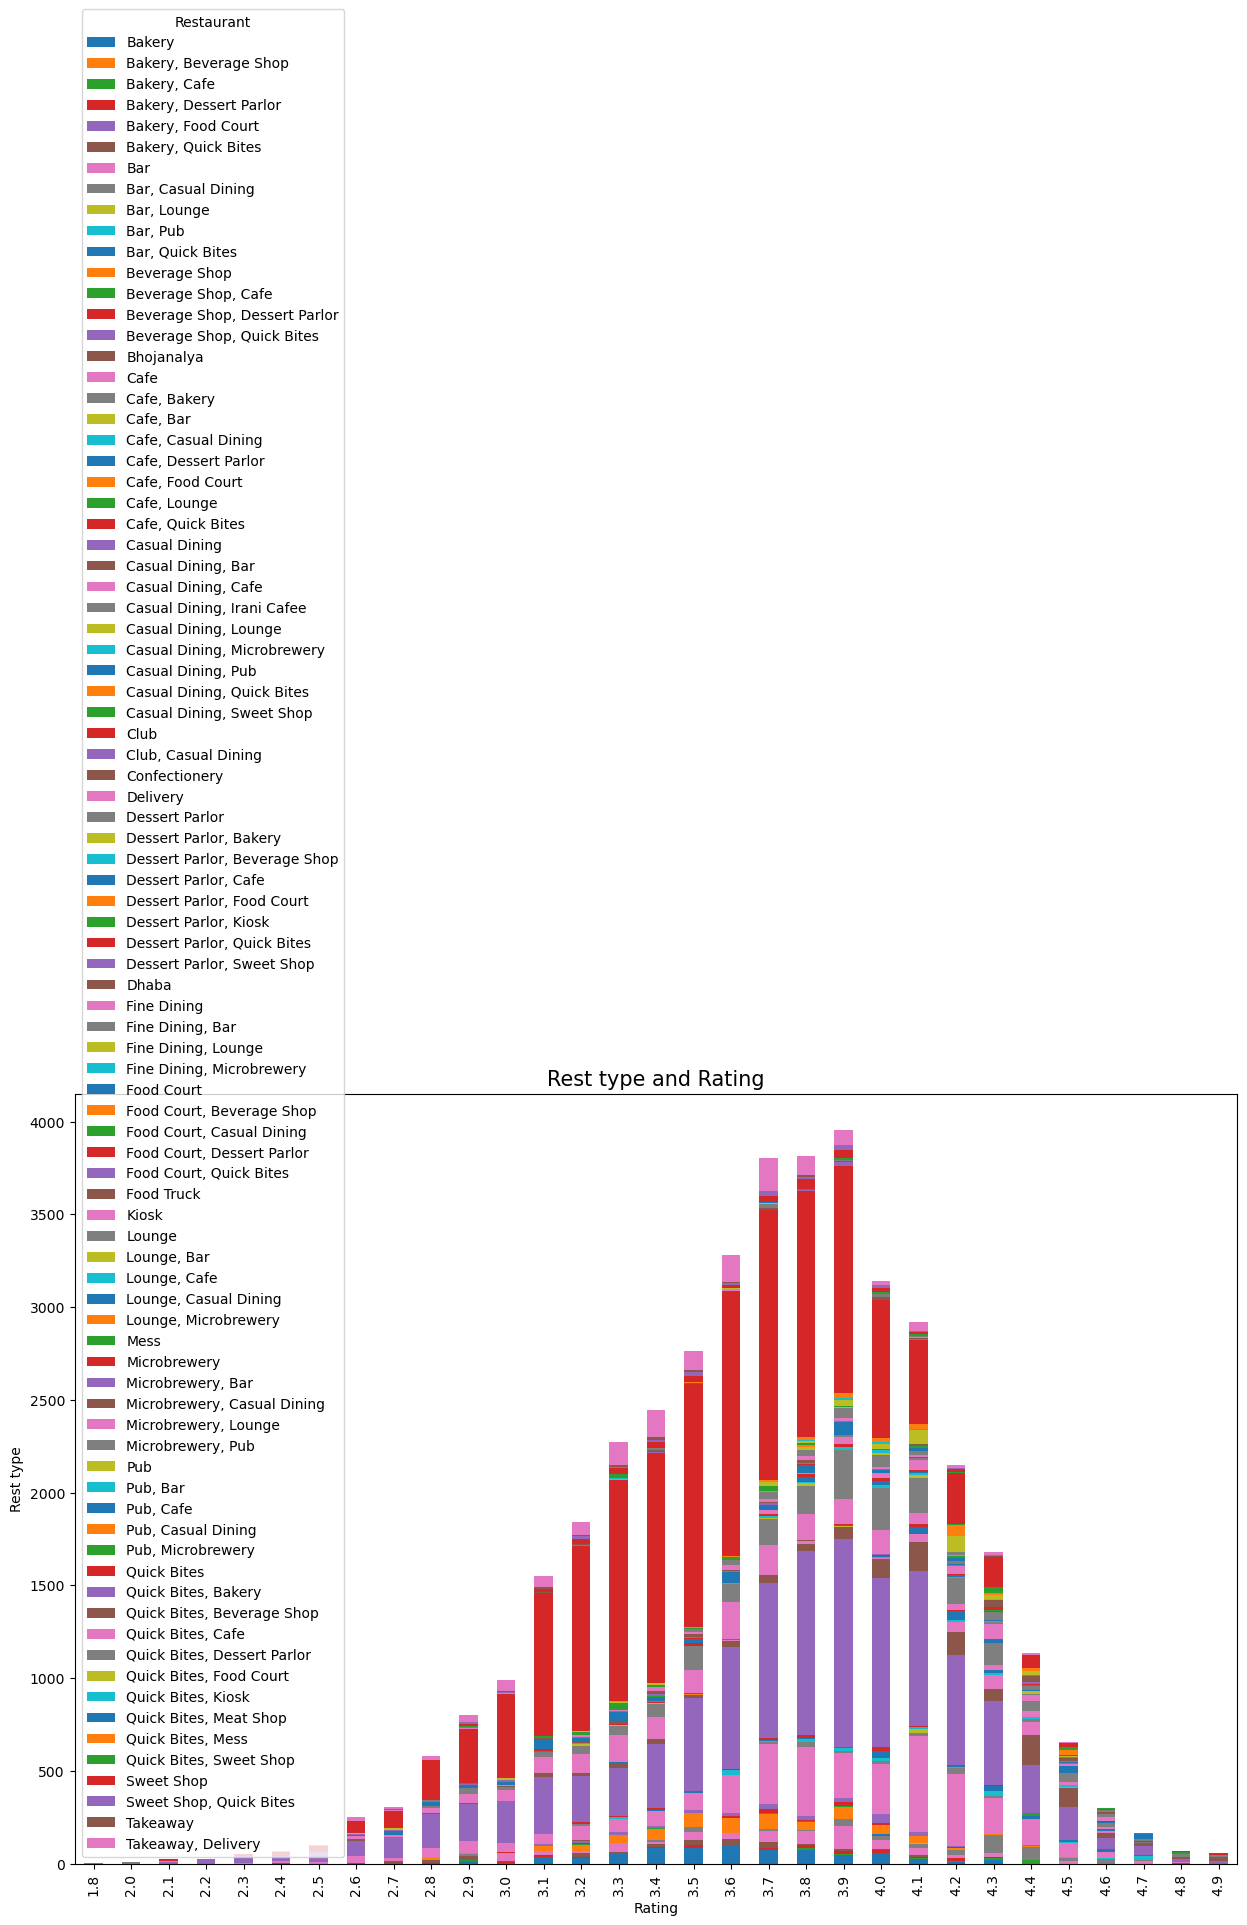

In [204]:
loc_plt=pd.crosstab(df['Rate'],df['Restaurant'])
loc_plt.plot(kind='bar', stacked='True', figsize=(15,10));
plt.title('Rest type and Rating', fontsize=15)
plt.ylabel('Rest type', fontsize=10)
plt.xlabel('Rating',fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10);

### 8. Types of Services

Text(0.5, 1.0, 'Types of Services')

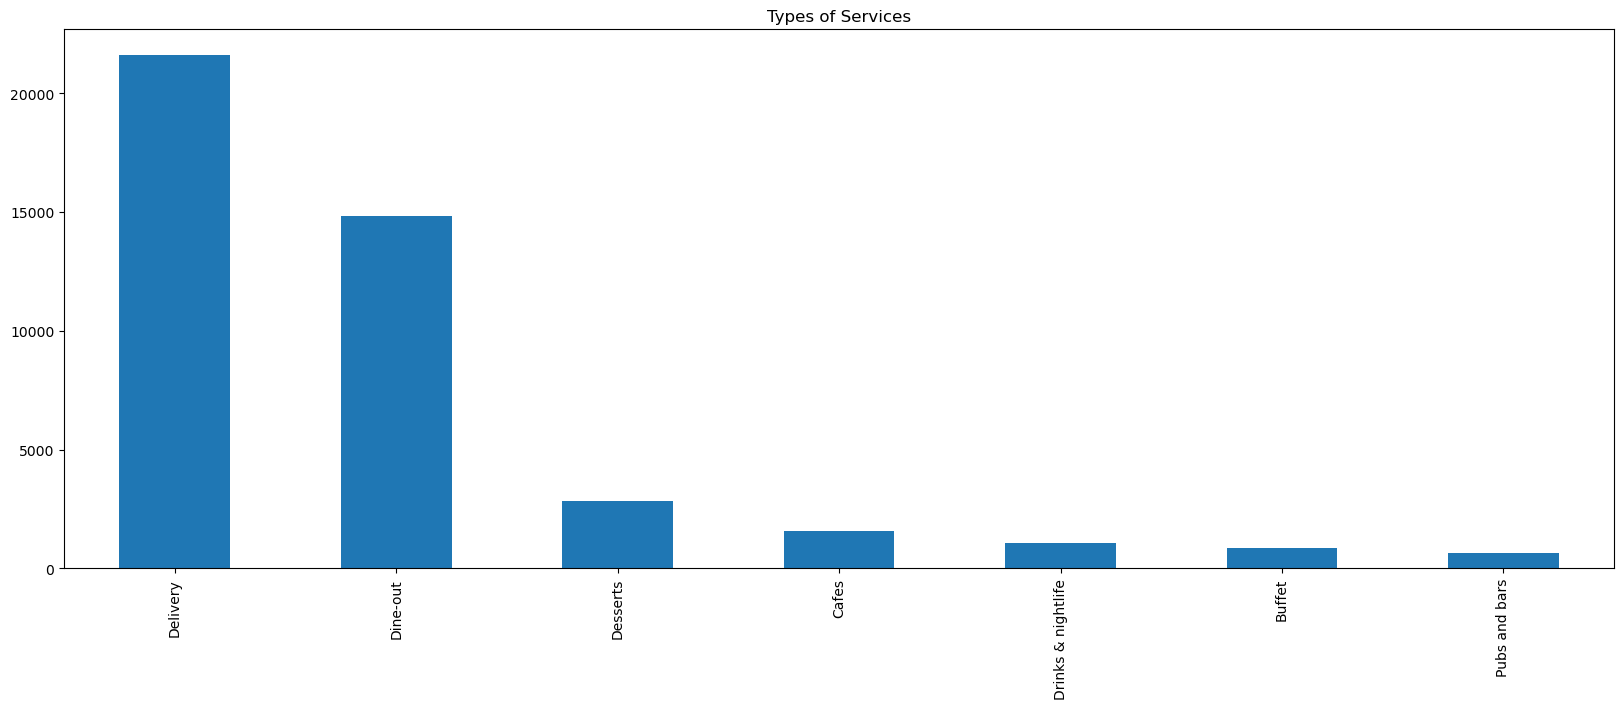

In [205]:
df['Type'].value_counts()[:].plot(kind='bar', figsize=(20,7))
plt.title('Types of Services')

### 9. Relation between Type and Rating


Text(0.5, 1.0, 'Relation between Type and Rating')

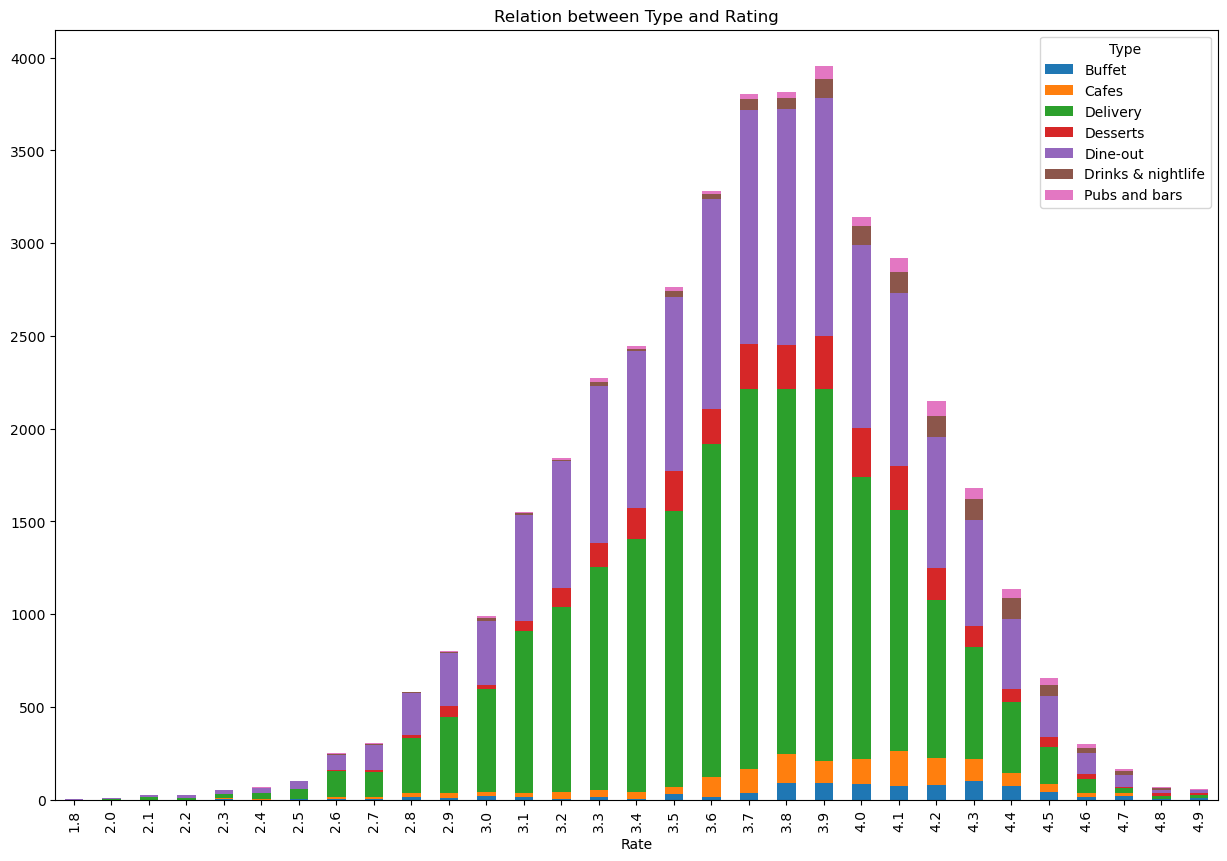

In [206]:
type_plt=pd.crosstab(df['Rate'],df['Type'])
type_plt.plot(kind='bar',stacked=True,figsize=(15,10));
plt.title('Relation between Type and Rating')

### 10. Cost of Restaurants

In [207]:
df.Cost
df.head()

,Name,Online_Orders,Table_Booking,Rate,Votes,Location,Restaurant,Cusines,Cost,Type,Listed_in(City)
0,Jalsa,Yes,Yes,4.1,775.0,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800,Buffet,Banashankari
1,Spice Elephant,Yes,No,4.1,787.0,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800,Buffet,Banashankari
2,San Churro Cafe,Yes,No,3.8,918.0,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800,Buffet,Banashankari
3,Addhuri Udupi Bhojana,No,No,3.7,88.0,Banashankari,Quick Bites,"South Indian, North Indian",300,Buffet,Banashankari
4,Grand Village,No,No,3.8,166.0,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600,Buffet,Banashankari


In [208]:
df['Cost'] = df['Cost'].str.replace(',', '')

Text(0.5, 1.0, 'Cost of Restuarants')

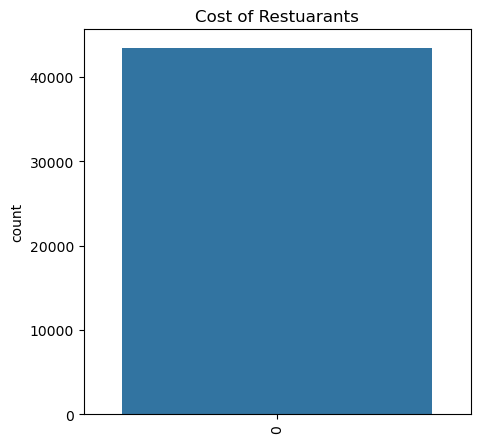

In [209]:
sns.countplot(df['Cost'])
sns.countplot(df['Cost']).set_xticklabels(sns.countplot(df['Cost']).get_xticklabels(), rotation=90)
fig = plt.gcf()
fig.set_size_inches(5,5)
plt.title('Cost of Restuarants')

### 11. No. of restaurants in a Location

Text(0.5, 1.0, 'No. of restaurants in a Location')

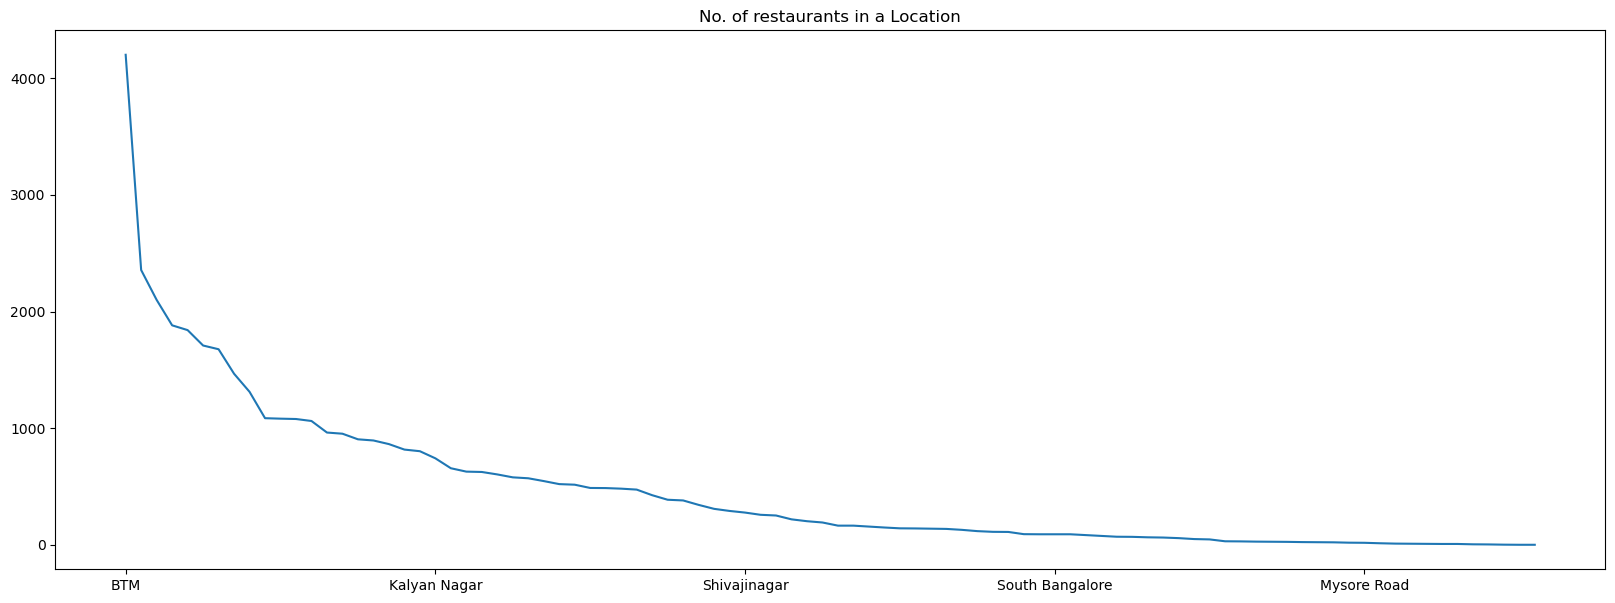

In [210]:
df['Location'].value_counts().plot(kind='line', figsize=(20,7))
plt.title('No. of restaurants in a Location')

### 12. Restaurant type

Text(0.5, 1.0, 'Type of Restaurant')

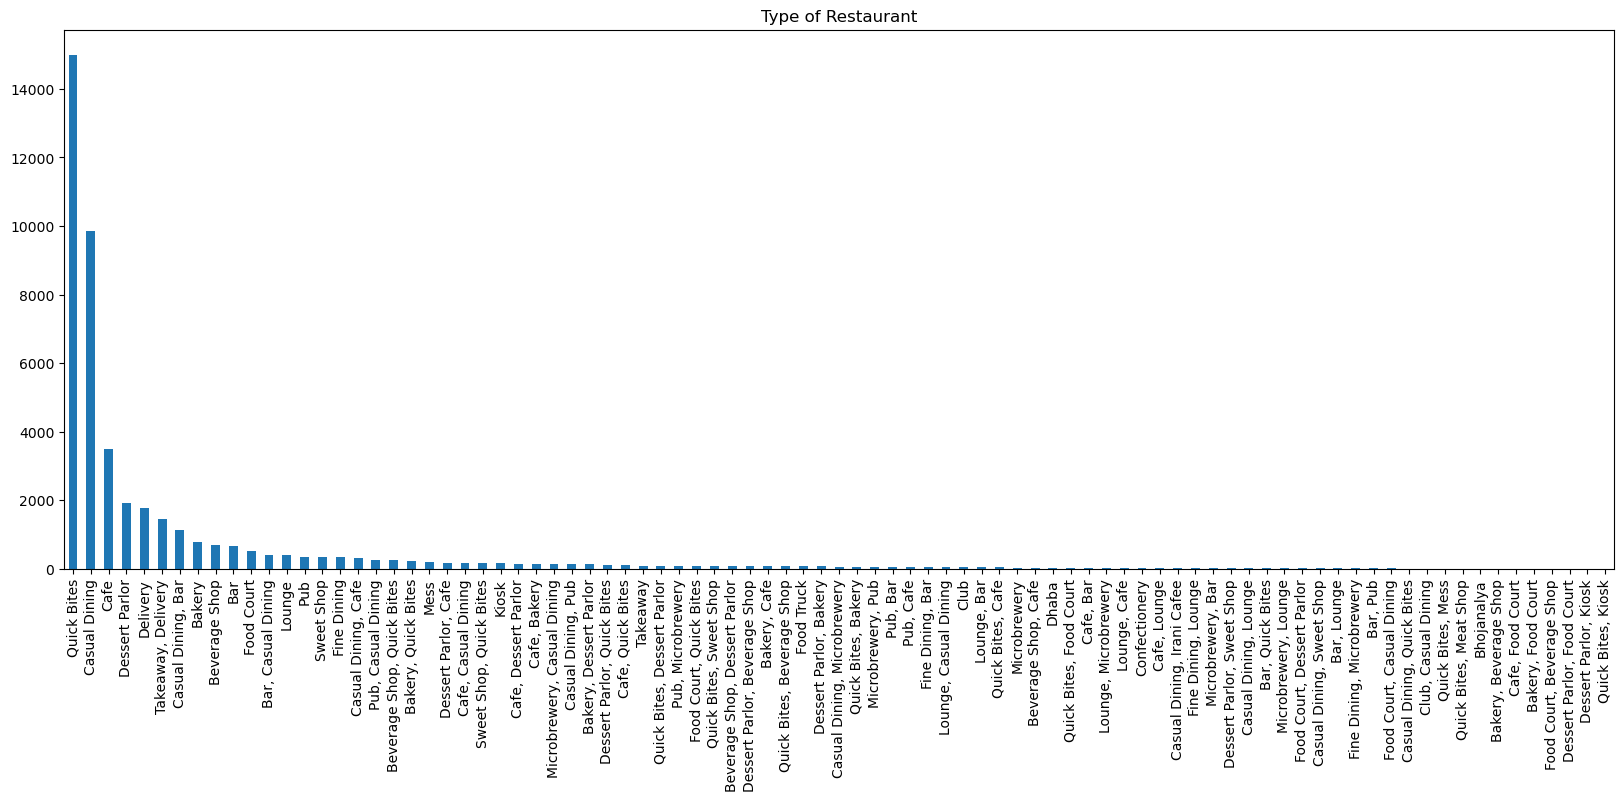

In [211]:
df['Restaurant'].value_counts().plot(kind='bar', figsize=(20,7))
plt.title('Type of Restaurant')

### 13. Most famous restaurant chains in Bengaluru

Text(0, 0.5, 'Restaurant_Name')

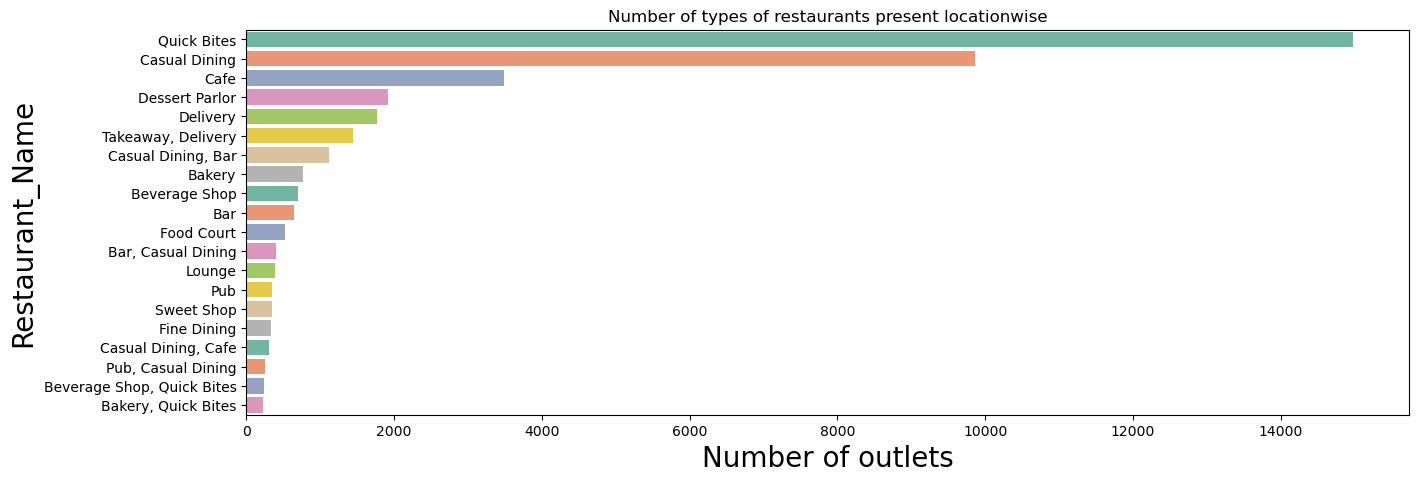

In [212]:
plt.figure(figsize=(15,5))
q=df['Restaurant'].value_counts()[:20]
sns.barplot(x=q,y=q.index,palette='Set2')
plt.title('Number of types of restaurants present locationwise')
plt.xlabel("Number of outlets",size=20)
plt.ylabel("Restaurant_Name",size=20)


### Write down the inferences about what you have learned from the dataset. i.e. Making sense of the data.

1. There are most of the restaurants which deliver online rather then offline.
2. Restaurants are mainly focused on online delivery of food.
3. Some of the restaurants usually do prior booking for the restaurant tables.
4. Prior table bookings have higher rate.
5. Mostly the best restaurants are located in BTM.
6. There are least number of fine dinning ,bars and the maximum number of Quick Bites.
7. Most of the restaurants maximum cost is 300 and minimum is 150.
8. Rating distribution has highest peak between 3.5 & 4.0 which is the most common rating for a restaurant in Bangaluru.
9. 
10. 

### What different problems we can solve through the dataset.

Problems such as :-
  1. Which is the top rated Restaurant ? 
  2. Which is the most costliest Restaurant ?
  3. Which is the msot crowded Restaurant ?
  4. Which is the most famous Restaurant nearby ?
  5. Which area has most number of Restaurants located ?
  6. Which Restaurants need to improve their Ambience and services towards the customers ?
  7. Which Restaurant has maximum number of outlets located ? 
  8. etc.....